# Notebook 02: Christoffel Symbols, Riemann Tensor, and Gaussian Curvature Flow Across Layers

## Research Objective
We compute the Levi-Civita connection (Christoffel symbols $\Gamma^{(\ell)k}_{ij}$) and intrinsic **Gaussian curvature** $K^{(\ell)}(x; \theta)$ of the 2D immersed representation manifolds $\mathcal{M}_\ell = \Phi^{(\ell)}_\theta(\mathbb{R}^2) \subset \mathbb{R}^{d_\ell}$ across layers $\ell \in \{1, 2, 3, 4, 5\}$:
$$\Gamma^{(\ell)}_{kij} = \frac{1}{2}\left(\partial_j g^{(\ell)}_{ki} + \partial_i g^{(\ell)}_{kj} - \partial_k g^{(\ell)}_{ij}\right), \qquad R^{(\ell)}_{1212} = -\frac{1}{2}\left(\partial_1^2 g^{(\ell)}_{22} - 2\partial_1\partial_2 g^{(\ell)}_{12} + \partial_2^2 g^{(\ell)}_{11}\right) + g^{(\ell)km}\left(\Gamma^{(\ell)}_{k12}\Gamma^{(\ell)}_{m12} - \Gamma^{(\ell)}_{k11}\Gamma^{(\ell)}_{m22}\right)$$
$$K^{(\ell)}(x) = \frac{R^{(\ell)}_{1212}(x)}{\det g^{(\ell)}(x)}, \qquad R_{\text{scalar}}^{(\ell)}(x) = 2 K^{(\ell)}(x)$$

### Key Mathematical Insight: The 2D-to-2D Euclidean Pullback Flatness Identity at Layer $\ell = 5$
- For hidden layers $\ell \in \{1, 2, 3, 4\}$ ($d_\ell \in \{5, 10, 15, 10\} > 2$), $\mathcal{M}_\ell$ is a 2D surface immersed in higher-dimensional Euclidean space $\mathbb{R}^{d_\ell}$, possessing rich non-zero intrinsic Gaussian curvature $K^{(\ell)}(x) \neq 0$.
- At the output layer $\ell = 5$ ($d_5 = 2$), pulling back the flat 2D Euclidean metric $I_2$ via a local diffeomorphism $z = f_\theta(x) \in \mathbb{R}^2$ is merely a coordinate change of flat Euclidean space, so $K^{(5)}_{\text{eucl}}(x) \equiv 0$!
- We empirically verify this identity and compare three non-degenerate output curvature constructions:
  1. **Graph Embedding Metric (Monge Patch in $\mathbb{R}^4$)**: $\tilde{g}^{(5)}_{ij}(x) = \delta_{ij} + ((J^{(5)}(x))^T J^{(5)}(x))_{ij}$.
  2. **Conformal Gaussian Output Metric**: $g^{(5)}_{\text{conf}}(x) = e^{-\|z(x)\|^2 / \sigma^2} (J^{(5)}(x))^T J^{(5)}(x)$.
  3. **Penultimate Surface Metric**: $g^{(4)}_{\text{eucl}}(x)$ on $\mathcal{M}_4 \subset \mathbb{R}^{10}$.

In [1]:
import sys
from pathlib import Path
for p in [Path.cwd(), Path.cwd().parent]:
    if (p / "src" / "geometry.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.geometry import (
    MoonsMLP,
    get_moons_dataset,
    make_evaluation_grid,
    compute_layer_geometry,
    _christoffel_and_curvature_from_g_single,
)

X_train, y_train, X_test, y_test = get_moons_dataset(n_train=360, n_test=180, noise=0.10, seed=42)
xx, yy, grid_pts = make_evaluation_grid(X_train, n_grid=26, padding=0.45)

# 1. Analytical validation on a sphere of radius R=2 (K = 1/R^2 = 0.25) and hyperbolic paraboloid (K(0) = -3.0)
R_s = 2.0
g_sphere = lambda x: ((2.0 * R_s**2 / (R_s**2 + torch.sum(x**2)))**2) * torch.eye(2, dtype=x.dtype)
_, _, _, K_sphere = _christoffel_and_curvature_from_g_single(g_sphere)(torch.tensor([0.8, -0.6], dtype=torch.float64))

g_saddle = lambda x: torch.eye(2, dtype=x.dtype) + torch.stack([2.0 * x[0], -1.5 * x[1]]).unsqueeze(0).T @ torch.stack([2.0 * x[0], -1.5 * x[1]]).unsqueeze(0)
_, _, _, K_saddle = _christoffel_and_curvature_from_g_single(g_saddle)(torch.zeros(2, dtype=torch.float64))

print(f"Analytical Validation | Sphere (R=2) exact K=0.250000 -> autodiff K={K_sphere.item():.6f}")
print(f"Analytical Validation | Hyperbolic Saddle exact K(0)=-3.000000 -> autodiff K={K_saddle.item():.6f}")

Analytical Validation | Sphere (R=2) exact K=0.250000 -> autodiff K=0.250000
Analytical Validation | Hyperbolic Saddle exact K(0)=-3.000000 -> autodiff K=-3.000000


## 1. Empirical Verification of 2D-to-2D Euclidean Flatness vs. Non-Degenerate Output Metrics
We train our `[2 -> 5 -> 10 -> 15 -> 10 -> 2]` MLP and compare the four curvature definitions at the output/penultimate layers.

In [2]:
model = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
optimizer = torch.optim.Adam(model.parameters(), lr=0.015)
criterion = nn.CrossEntropyLoss()

epoch_snapshots = {0: copy.deepcopy(model.state_dict())}
for ep in range(1, 201):
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()
    if ep in [20, 70, 200]:
        epoch_snapshots[ep] = copy.deepcopy(model.state_dict())

geom_l5_eucl = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="euclidean", eps=1e-13)
geom_l5_graph = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="graph")
geom_l5_conf = compute_layer_geometry(model, X_test[:50], layer_idx=5, metric_mode="conformal_gaussian", sigma=2.5)
geom_l4_eucl = compute_layer_geometry(model, X_test[:50], layer_idx=4, metric_mode="euclidean", eps=1e-7)

print("Comparison of Curvature Formulations on Trained Network (50 test points):")
print(f"  1. Layer 5 Flat Euclidean Pullback (d=2 -> d=2) : max |K| = {geom_l5_eucl['K'].abs().max().item():.2e} (Identically Flat!)")
print(f"  2. Layer 5 Graph Immersion Metric in R^4        : mean |K| = {geom_l5_graph['K'].abs().mean().item():.4f}, range = [{geom_l5_graph['K'].min().item():.3f}, {geom_l5_graph['K'].max().item():.3f}]")
print(f"  3. Layer 5 Conformal Gaussian Output Metric     : mean |K| = {geom_l5_conf['K'].abs().mean().item():.4f}, range = [{geom_l5_conf['K'].min().item():.3f}, {geom_l5_conf['K'].max().item():.3f}]")
print(f"  4. Layer 4 Penultimate Immersion in R^10        : mean |K| = {geom_l4_eucl['K'].abs().mean().item():.4f}, range = [{geom_l4_eucl['K'].min().item():.3f}, {geom_l4_eucl['K'].max().item():.3f}]")

Comparison of Curvature Formulations on Trained Network (50 test points):
  1. Layer 5 Flat Euclidean Pullback (d=2 -> d=2) : max |K| = 1.21e-05 (Identically Flat!)
  2. Layer 5 Graph Immersion Metric in R^4        : mean |K| = 0.2061, range = [-0.362, 4.610]
  3. Layer 5 Conformal Gaussian Output Metric     : mean |K| = 52489.6960, range = [-178503.966, 790900.828]
  4. Layer 4 Penultimate Immersion in R^10        : mean |K| = 1.5564, range = [-4.730, 24.755]


## 2. Layerwise Gaussian Curvature Landscape $K^{(\ell)}(x)$ Across Network Depth
We plot $\operatorname{arcsinh}(K^{(\ell)}(x))$ across layers $\ell = 1, 2, 3, 4$ (Euclidean immersion in $\mathbb{R}^{d_\ell}$) and layer $\ell = 5$ (Graph immersion in $\mathbb{R}^4$).
Notice how **Brandon, Chadwick, & Pellegrino (2025)**'s two-stage geometric decomposition appears:
- **Early expansion layers ($\ell = 1, 2, 3$)** introduce localized positive and negative curvature folds along the moon crescents to discretize continuous input coordinates.
- **Contraction layers ($\ell = 4, 5$)** concentrate sharp curvature ridges along the decision boundary while flattening the interior of each class manifold (discrete Ricci flow smoothing; **Baptista et al., 2024**; **Hehl et al., 2025**).

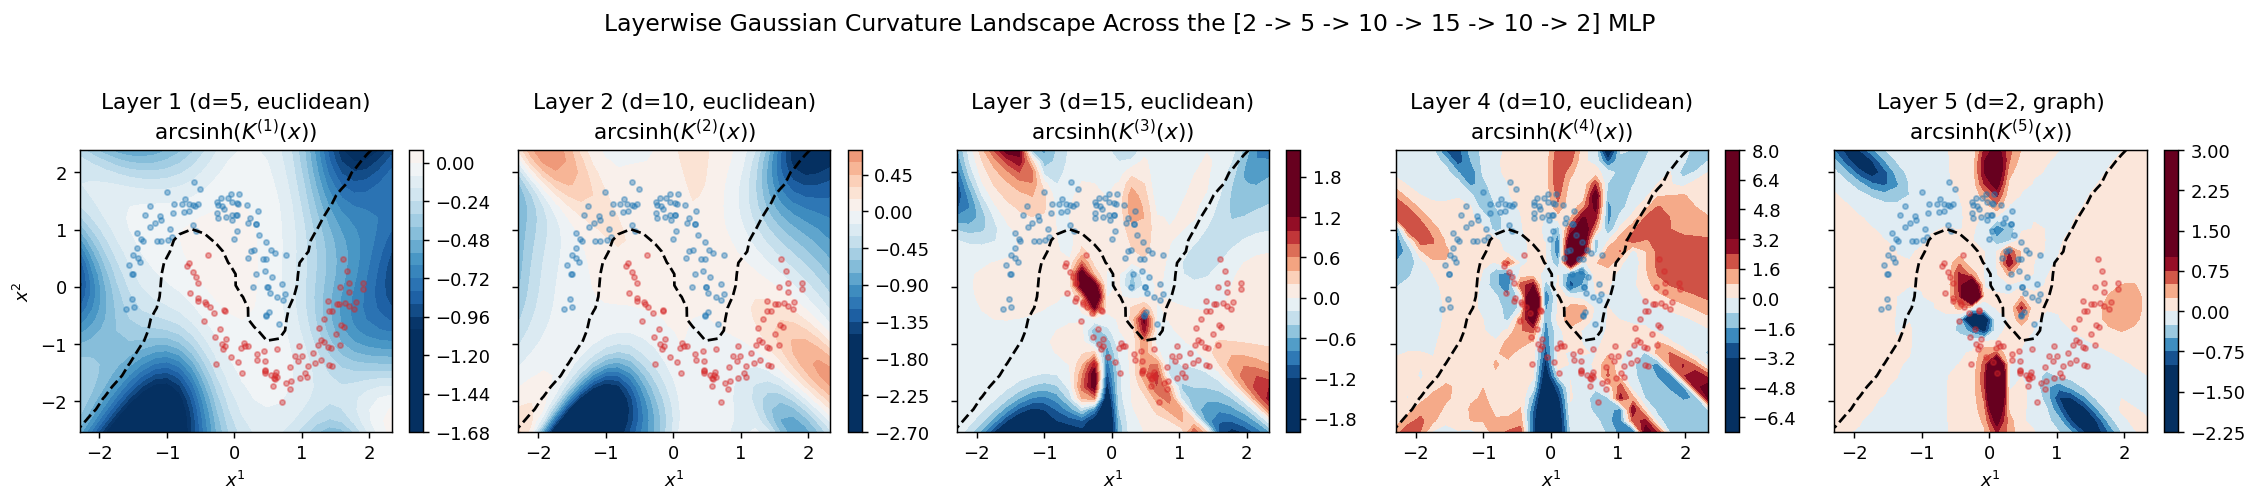

In [3]:
with torch.no_grad():
    probs_grid = torch.softmax(model(grid_pts), dim=-1)[:, 1].reshape(xx.shape).numpy()

fig, axes = plt.subplots(1, 5, figsize=(17.5, 3.7), sharex=True, sharey=True)
for idx, l_idx in enumerate(range(1, 6)):
    mode = "graph" if l_idx == 5 else "euclidean"
    geom = compute_layer_geometry(model, grid_pts, layer_idx=l_idx, metric_mode=mode, eps=1e-6)
    K_map = np.arcsinh(geom["K"].detach().numpy().reshape(xx.shape))
    vmax = max(np.percentile(np.abs(K_map), 96), 0.1)

    im = axes[idx].contourf(xx, yy, K_map, levels=22, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[idx].contour(xx, yy, probs_grid, levels=[0.5], colors="k", linewidths=1.5, linestyles="--")
    axes[idx].scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="#1f77b4", s=8, alpha=0.4)
    axes[idx].scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="#d62728", s=8, alpha=0.4)
    axes[idx].set_title(f"Layer {l_idx} (d={model.layer_dims[l_idx]}, {mode})\n$\mathrm{{arcsinh}}(K^{{({l_idx})}}(x))$")
    axes[idx].set_xlabel("$x^1$")
    plt.colorbar(im, ax=axes[idx], fraction=0.046)

axes[0].set_ylabel("$x^2$")
plt.suptitle("Layerwise Gaussian Curvature Landscape Across the [2 -> 5 -> 10 -> 15 -> 10 -> 2] MLP", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Evolution of Layerwise Curvature & Christoffel Symbol Norms Across Training Epochs
We track how the mean magnitude of Gaussian curvature $\mathbb{E}[|K^{(\ell)}(x)|]$ and Christoffel connection norm $\mathbb{E}[\|\Gamma^{(\ell)}(x)\|_F]$ evolve across layers $\ell \in \{1,\dots,5\}$ from initialization ($t=0$) to convergence ($t=200$), contrasting interior class points against decision-boundary points ($|P(y=1|x) - 0.5| < 0.15$).

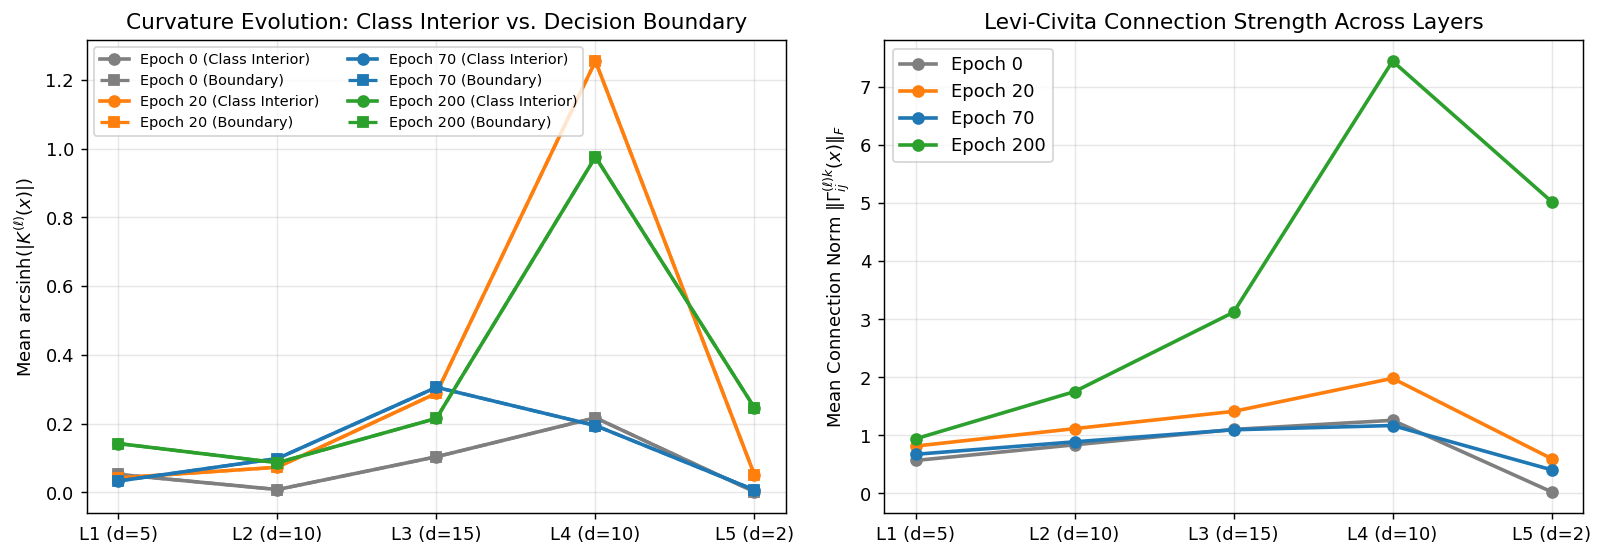

In [4]:
with torch.no_grad():
    p_tr = torch.softmax(model(X_train), dim=-1)[:, 1]
    boundary_mask = (p_tr - 0.5).abs() < 0.20
    interior_mask = ~boundary_mask

probe = MoonsMLP(layer_dims=(2, 5, 10, 15, 10, 2), activation="tanh", seed=42)
epochs_list = [0, 20, 70, 200]
layers_list = [1, 2, 3, 4, 5]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
colors = ["#7f7f7f", "#ff7f0e", "#1f77b4", "#2ca02c"]

for ep, col in zip(epochs_list, colors):
    probe.load_state_dict(epoch_snapshots[ep])
    k_int, k_bnd, gamma_norms = [], [], []
    for l_idx in layers_list:
        mode = "graph" if l_idx == 5 else "euclidean"
        g_tr = compute_layer_geometry(probe, X_train, layer_idx=l_idx, metric_mode=mode, eps=1e-6)
        k_abs = torch.arcsinh(g_tr["K"].abs()).detach()
        k_int.append(k_abs[interior_mask].mean().item())
        k_bnd.append(k_abs[boundary_mask].mean().item() if boundary_mask.any() else k_abs.mean().item())
        gamma_norms.append(g_tr["christoffel"].flatten(1).norm(dim=1).mean().item())

    axes[0].plot(layers_list, k_int, marker="o", lw=2, color=col, label=f"Epoch {ep} (Class Interior)")
    axes[0].plot(layers_list, k_bnd, marker="s", lw=1.8, ls="--", color=col, label=f"Epoch {ep} (Boundary)")
    axes[1].plot(layers_list, gamma_norms, marker="o", lw=2, color=col, label=f"Epoch {ep}")

axes[0].set_xticks(layers_list)
axes[0].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[0].set_ylabel("Mean $\mathrm{arcsinh}(|K^{(\ell)}(x)|)$")
axes[0].set_title("Curvature Evolution: Class Interior vs. Decision Boundary")
axes[0].legend(fontsize=8, ncol=2)
axes[0].grid(alpha=0.3)

axes[1].set_xticks(layers_list)
axes[1].set_xticklabels([f"L{l} (d={model.layer_dims[l]})" for l in layers_list])
axes[1].set_ylabel("Mean Connection Norm $\|\Gamma^{(\ell)k}_{ij}(x)\|_F$")
axes[1].set_title("Levi-Civita Connection Strength Across Layers")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()